# Validasi eksternal modul skrining 5 butir pada data klinis independen (NHANES 2017–Maret 2020)

Menjawab komentar editor HISS: *"validated using more recent data and independent clinical data"*.

- **Data**: NHANES 2017–Maret 2020 (pra-pandemi), Amerika Serikat. Ini data publik, boleh diunduh dan dibagikan.
- **Pengukuran CRP**: hs-CRP serum vena di laboratorium klinis, berbeda dari dried blood spot di IFLS-5, sehingga sekaligus menguji apakah model bertahan pada metode laboratorium klinis.
- **Model**: rumus modul 5 butir **persis seperti di model card** (koefisien dan kalibrasi Platt dari IFLS-5, *tidak dilatih ulang*).
- **Kriteria sampel** dibuat sama dengan IFLS-5: umur ≥15 tahun, tidak hamil, hs-CRP ≤10 mg/L, outcome hs-CRP ≥3 mg/L.
- **Kesehatan subjektif**: HUQ010 "fair" atau "poor" = poor self-rated health.
- **Kota/desa**: NHANES publik tidak memuat status kota/desa. Karena hanya menggeser konstanta, AUC tidak berubah; kalibrasi dilaporkan untuk skenario urban = 1 (utama, ±80% penduduk AS tinggal di kota) dan urban = 0.

File NHANES disimpan di `F:\NHANES 2027\data\raw` (folder yang sudah ada). Hasil: `results/validasi_eksternal_nhanes.xlsx` dan gambar `figS_external_*`.

In [1]:
# === SEL 1: pengaturan dan unduh data NHANES ===
import os, time, urllib.request
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, brier_score_loss
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import calibration_curve
from scipy.optimize import brentq

ROOT = r"F:\SINTA 3\crp-ifls5-ml"
RAW = r"F:\NHANES 2027\data\raw"
OUTDIR = os.path.join(ROOT, 'results'); os.makedirs(OUTDIR, exist_ok=True); os.makedirs(RAW, exist_ok=True)
BASE = "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/{name}.xpt"
SEED = 42; rng = np.random.default_rng(SEED); N_BOOT = 1000

def get_xpt(name):
    dest = os.path.join(RAW, f'{name}.xpt')
    if not (os.path.exists(dest) and os.path.getsize(dest) > 0):
        req = urllib.request.Request(BASE.format(name=name), headers={'User-Agent': 'Mozilla/5.0 (research download)'})
        data = urllib.request.urlopen(req, timeout=180).read()
        if not data.startswith(b'HEADER RECORD'):
            raise ValueError(f'{name}: isi bukan file XPT; unduh manual dari situs NHANES lalu simpan di {RAW}')
        open(dest, 'wb').write(data); print('diunduh:', name)
    return pd.read_sas(dest, format='xport')

demo, bmx, huq, crp = (get_xpt(n) for n in ['P_DEMO', 'P_BMX', 'P_HUQ', 'P_HSCRP'])
print({n: len(d) for n, d in zip(['DEMO', 'BMX', 'HUQ', 'HSCRP'], [demo, bmx, huq, crp])})

diunduh: P_HUQ
diunduh: P_HSCRP
{'DEMO': 15560, 'BMX': 14300, 'HUQ': 15560, 'HSCRP': 13772}


In [2]:
# === SEL 2: bangun sampel dengan kriteria yang sama dengan IFLS-5 ===
d = (demo[['SEQN', 'RIDAGEYR', 'RIAGENDR', 'RIDEXPRG', 'WTMECPRP', 'RIDRETH3', 'INDFMPIR']]
     .merge(bmx[['SEQN', 'BMXBMI']], on='SEQN', how='left')
     .merge(huq[['SEQN', 'HUQ010']], on='SEQN', how='left')
     .merge(crp[['SEQN', 'LBXHSCRP']], on='SEQN', how='left'))
flow = [('Peserta NHANES 2017–Mar 2020', len(d))]
d = d[d.RIDAGEYR >= 15]; flow.append(('Umur ≥15 tahun', len(d)))
d = d[d.RIDEXPRG != 1]; flow.append(('Tidak hamil', len(d)))
d = d[d.LBXHSCRP.notna()]; flow.append(('Ada hasil hs-CRP', len(d)))
d = d[d.LBXHSCRP <= 10]; flow.append(('hs-CRP ≤10 mg/L (sama dengan IFLS-5)', len(d)))
d = d[d.BMXBMI.notna() & d.HUQ010.isin([1, 2, 3, 4, 5])]; flow.append(('BMI dan kesehatan subjektif lengkap', len(d)))
FLOW = pd.DataFrame(flow, columns=['Langkah', 'n']); display(FLOW)

d['y'] = (d.LBXHSCRP >= 3).astype(int)
d['female'] = (d.RIAGENDR == 2).astype(int)
d['srh_poor'] = d.HUQ010.isin([4, 5]).astype(int)
d['age'] = d.RIDAGEYR; d['bmi'] = d.BMXBMI
print(f'n = {len(d):,}; kasus hs-CRP ≥3 mg/L = {d.y.sum():,} ({d.y.mean()*100:.1f}%)')

,Langkah,n
0,Peserta NHANES 2017–Mar 2020,15560
1,Umur ≥15 tahun,10428
2,Tidak hamil,10341
3,Ada hasil hs-CRP,8770
4,hs-CRP ≤10 mg/L (sama dengan IFLS-5),8088
5,BMI dan kesehatan subjektif lengkap,7958


n = 7,958; kasus hs-CRP ≥3 mg/L = 2,360 (29.7%)


In [3]:
# === SEL 3: terapkan rumus model card IFLS-5 (tanpa pelatihan ulang) ===
B0, B = -3.297376, {'bmi': 0.111012, 'female': 0.235002, 'age': 0.006115, 'srh_poor': 0.434532, 'urban': 0.227531}
A_PLATT, B_PLATT, THR_LP, THR_P = -1.722548, 0.986826, 0.028441, 0.155187
def predict(frame, urban):
    lp = B0 + sum(B[k] * frame[k] for k in ['bmi', 'female', 'age', 'srh_poor']) + B['urban'] * urban
    return lp.values, 1 / (1 + np.exp(-(A_PLATT + B_PLATT * lp.values)))
y = d.y.values; w = d.WTMECPRP.values
lp1, p1 = predict(d, 1); lp0, p0 = predict(d, 0)

def logit(p): p = np.clip(p, 1e-6, 1 - 1e-6); return np.log(p / (1 - p))
def cal(yt, p):
    l = logit(p)
    citl = brentq(lambda a: (1 / (1 + np.exp(-(l + a)))).mean() - yt.mean(), -10, 10)
    slope = LogisticRegression(C=1e6, max_iter=1000).fit(l.reshape(-1, 1), yt).coef_[0][0]
    return citl, slope
def perf(yt, p, thr=THR_P):
    pr = p >= thr; tp = (pr & (yt == 1)).sum(); fn = (~pr & (yt == 1)).sum(); fp = (pr & (yt == 0)).sum(); tn = (~pr & (yt == 0)).sum()
    citl, slope = cal(yt, p)
    return {'AUC': roc_auc_score(yt, p), 'Brier': brier_score_loss(yt, p), 'Calibration intercept': citl, 'Calibration slope': slope,
            'O/E': yt.mean() / p.mean(), 'Flagged (%)': pr.mean() * 100, 'Sensitivity': tp / (tp + fn), 'Specificity': tn / (tn + fp),
            'PPV': tp / max(tp + fp, 1), 'NPV': tn / max(tn + fn, 1)}

# pembaruan model sederhana yang lazim untuk validasi eksternal (tanpa mengubah urutan risiko):
# (a) pembaruan intercept saja, (b) kalibrasi ulang logistik (intercept + slope)
upd_a = brentq(lambda a: (1 / (1 + np.exp(-(logit(p1) + a)))).mean() - y.mean(), -10, 10)
p1_a = 1 / (1 + np.exp(-(logit(p1) + upd_a)))
lr_b = LogisticRegression(C=1e6, max_iter=1000).fit(logit(p1).reshape(-1, 1), y); p1_b = lr_b.predict_proba(logit(p1).reshape(-1, 1))[:, 1]
SETTINGS = {'Original formula, urban = 1': p1, 'Original formula, urban = 0': p0,
            'Intercept updated (urban = 1)': p1_a, 'Logistic recalibration (urban = 1)': p1_b}
boot = [rng.integers(0, len(y), len(y)) for _ in range(N_BOOT)]
rows = []
for name, p in SETTINGS.items():
    est = perf(y, p); bs = pd.DataFrame([perf(y[b], p[b]) for b in boot[:300]])
    for k, v in est.items():
        rows.append({'Setting': name, 'Metric': k, 'Estimate': round(v, 3),
                     '95% CI': f'{bs[k].quantile(.025):.3f}–{bs[k].quantile(.975):.3f}'})
EXT = pd.DataFrame(rows)
display(EXT.pivot(index='Setting', columns='Metric', values='Estimate').loc[list(SETTINGS)])
print('Weighted AUC (bobot MEC):', round(roc_auc_score(y, p1, sample_weight=w), 3))
print(f'Pembaruan intercept = {upd_a:+.3f} log-odds; kalibrasi ulang logistik: a = {lr_b.intercept_[0]:.3f}, b = {lr_b.coef_[0][0]:.3f}')

Metric,AUC,Brier,Calibration intercept,Calibration slope,Flagged (%),NPV,O/E,PPV,Sensitivity,Specificity
Setting,,,,,,,,,,
"Original formula, urban = 1",0.747,0.176,0.110,1.146,75.886,0.906,1.071,0.361,0.924,0.311
"Original formula, urban = 0",0.747,0.180,0.335,1.146,64.966,0.887,1.237,0.396,0.867,0.442
Intercept updated (urban = 1),0.747,0.175,0.000,1.145,80.925,0.914,1.000,0.346,0.944,0.248
Logistic recalibration (urban = 1),0.747,0.175,-0.000,1.000,75.697,0.906,1.000,0.362,0.923,0.313


Weighted AUC (bobot MEC): 0.744
Pembaruan intercept = +0.110 log-odds; kalibrasi ulang logistik: a = 0.243, b = 1.146


,Attribute,Group,n,Prevalence (%),AUC,Calibration intercept,O/E,Sensitivity,Specificity,NPV
0,Sex,Female,3953,33.8,0.761,0.060,1.034,0.964,0.230,0.926
1,Sex,Male,4005,25.5,0.721,-0.064,0.958,0.919,0.264,0.904
2,Age group,15–39,3054,23.9,0.798,-0.049,0.968,0.886,0.443,0.925
3,Age group,40–59,2329,34.7,0.732,0.133,1.080,0.970,0.151,0.906
4,Age group,≥60,2575,31.8,0.675,-0.072,0.958,0.971,0.073,0.842
5,Race/ethnicity,Mexican American,997,29.0,0.725,-0.111,0.933,0.955,0.153,0.893
6,Race/ethnicity,NH Asian,1001,17.9,0.730,-0.239,0.836,0.877,0.365,0.932
7,Race/ethnicity,NH Black,1937,33.8,0.760,0.061,1.035,0.957,0.257,0.922
8,Race/ethnicity,NH White,2790,29.4,0.748,-0.022,0.987,0.946,0.232,0.912
9,Race/ethnicity,Other Hispanic,820,35.1,0.721,0.223,1.142,0.962,0.186,0.900


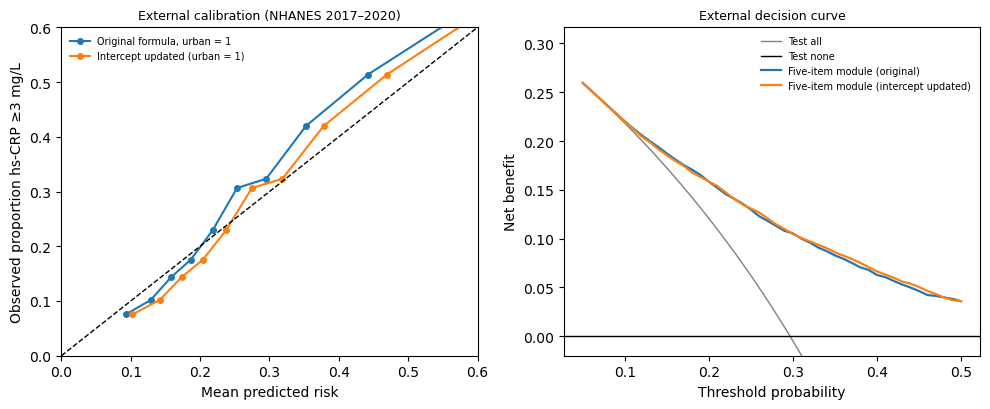

In [4]:
# === SEL 4: per subkelompok (jenis kelamin, umur, ras/etnis) dan DCA ===
grp = {'Sex': d.female.map({0: 'Male', 1: 'Female'}), 'Age group': pd.cut(d.age, [0, 39, 59, 200], labels=['15–39', '40–59', '≥60']).astype(str),
       'Race/ethnicity': d.RIDRETH3.map({1: 'Mexican American', 2: 'Other Hispanic', 3: 'NH White', 4: 'NH Black', 6: 'NH Asian', 7: 'Other/multiracial'})}
rows = []
for attr, g in grp.items():
    for lvl in sorted(g.dropna().unique()):
        m = (g == lvl).values
        if m.sum() < 100: continue
        e = perf(y[m], p1_a[m])
        rows.append({'Attribute': attr, 'Group': lvl, 'n': int(m.sum()), 'Prevalence (%)': round(y[m].mean() * 100, 1),
                     **{k: round(v, 3) for k, v in e.items() if k in ['AUC', 'Calibration intercept', 'O/E', 'Sensitivity', 'Specificity', 'NPV']}})
EXT_SUB = pd.DataFrame(rows); display(EXT_SUB)

TH = np.round(np.arange(0.05, 0.501, 0.01), 2); prev = y.mean()
def nb(yt, p, t): n = len(yt); return ((p >= t) & (yt == 1)).sum() / n - ((p >= t) & (yt == 0)).sum() / n * t / (1 - t)
DCA_EXT = pd.DataFrame({'Threshold': TH, 'Test all': [prev - (1 - prev) * t / (1 - t) for t in TH], 'Test none': 0.0,
                        'Five-item module (original)': [nb(y, p1, t) for t in TH],
                        'Five-item module (intercept updated)': [nb(y, p1_a, t) for t in TH]})

fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
for name in ['Original formula, urban = 1', 'Intercept updated (urban = 1)']:
    fy, fx = calibration_curve(y, SETTINGS[name], n_bins=10, strategy='quantile'); ax[0].plot(fx, fy, 'o-', ms=4, label=name)
mx = max(.6, y.mean() * 2); ax[0].plot([0, mx], [0, mx], 'k--', lw=1); ax[0].set_xlim(0, mx); ax[0].set_ylim(0, mx)
ax[0].set_xlabel('Mean predicted risk'); ax[0].set_ylabel('Observed proportion hs-CRP ≥3 mg/L'); ax[0].legend(fontsize=7, frameon=False)
ax[0].set_title('External calibration (NHANES 2017–2020)', fontsize=9)
ax[1].plot(TH, DCA_EXT['Test all'], color='grey', lw=1, label='Test all'); ax[1].axhline(0, color='k', lw=1, label='Test none')
for c in ['Five-item module (original)', 'Five-item module (intercept updated)']: ax[1].plot(TH, DCA_EXT[c], lw=1.6, label=c)
ax[1].set_ylim(-0.02, prev + 0.02); ax[1].set_xlabel('Threshold probability'); ax[1].set_ylabel('Net benefit')
ax[1].legend(fontsize=7, frameon=False); ax[1].set_title('External decision curve', fontsize=9)
plt.tight_layout()
for ext in ['png', 'tiff']: plt.savefig(os.path.join(OUTDIR, f'figS_external_nhanes.{ext}'), dpi=300)
plt.show()

In [5]:
# === SEL 5: simpan hasil ===
desc = pd.DataFrame({'Characteristic': ['n', 'Age, mean (SD)', 'Female (%)', 'BMI, mean (SD)', 'Poor/fair self-rated health (%)', 'hs-CRP ≥3 mg/L (%)'],
                     'NHANES 2017–2020': [len(d), f'{d.age.mean():.1f} ({d.age.std():.1f})', f'{d.female.mean()*100:.1f}',
                                          f'{d.bmi.mean():.1f} ({d.bmi.std():.1f})', f'{d.srh_poor.mean()*100:.1f}', f'{y.mean()*100:.1f}']})
with pd.ExcelWriter(os.path.join(OUTDIR, 'validasi_eksternal_nhanes.xlsx')) as xw:
    FLOW.to_excel(xw, sheet_name='alur_sampel', index=False)
    desc.to_excel(xw, sheet_name='karakteristik', index=False)
    EXT.to_excel(xw, sheet_name='performa', index=False)
    EXT_SUB.to_excel(xw, sheet_name='subkelompok', index=False)
    DCA_EXT.round(4).to_excel(xw, sheet_name='dca', index=False)
print('Tersimpan: results/validasi_eksternal_nhanes.xlsx dan figS_external_nhanes.png/.tiff')

Tersimpan: results/validasi_eksternal_nhanes.xlsx dan figS_external_nhanes.png/.tiff
